# Solving Inverse Problem using Connectome Spectrum Electromagnetic Tomography (CSET)

In this section we will solve the inverse problem using our new method CSET. This requires the eeg measurements, the forward solution and the connectome spectrum transform (prior). <br>
The method solves the following problem: $$\vec{x}^* = \text{argmin}_{\vec{x}} \lVert A\vec{x}-b \rVert_2^2 + \lambda \lVert F\vec{x}\rVert_1$$
where
- $\vec{x}^* \in \mathbb{R}^n$ is the reconstructed brain activity.
- $\vec{x} \in \mathbb{R}^n$ is the brain activity.
- $\vec{b} \in \mathbb{R}^m$ are the eeg measurements.
- $A \in \mathbb{R}^{m\times n}$ is the forward matrix.
- $F \in \mathbb{R}^{n \times n}$ is the connectome spectrum transform.
- $\lambda \in \mathbb{R}$ is the regularizer parameter.

Regularizing with $\lVert F\vec{x} \rVert_1$ imposes the connectome spectrum of $\vec{x}$ to be sparse and $\lambda$ 

## 📦 Imports

In [1]:
#%matplotlib qt

import mindmap as mm
import mne
import numpy as np
from pathlib import Path

import pyxu.abc as pxa
import pyxu.operator as pxo 
import pyxu.opt.stop as pxst
from pyxu.opt.solver import PGD

## 🧠 Data

In [19]:
# configuration
sub    = "sub-pat06"
config = mm.io.read_config("../configurations/spike.yml")

# data
data = mm.io.read_dataset(sub, "fwd", "cst", "eeg_inv")

fwd = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
fwd = fwd["sol"]["data"].astype("float64")                                              # forward matrix

# parameters
lam           = 0.00001
initial_guess = "adjoint"

# pyxu parameters
pyxu_kwargs = dict(
    folder = "solverOutput/",
    exist_ok = True,
    writeback_rate = 1000,
    verbosity = 1,
    show_progress = False,
    log_var = "x",
)

FileNotFoundError: File does not exist: "/media/nino/DATA/SPIKE/derivatives/mindmap/sub-pat06/eeg/sub-pat06_coreg_ave.fif"

#### 🌟 Visualize EEG time series

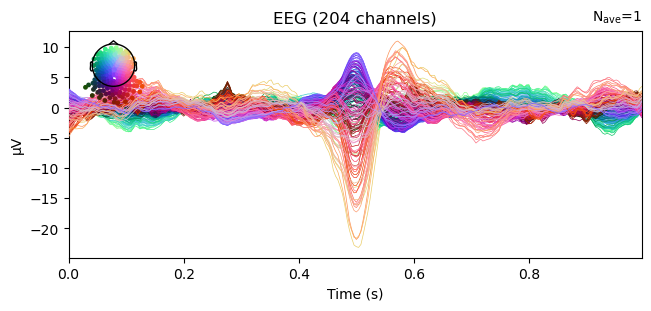

In [5]:
_ = data["eeg_inv"].plot()

#### 🌟 Visualize EEG topographic maps

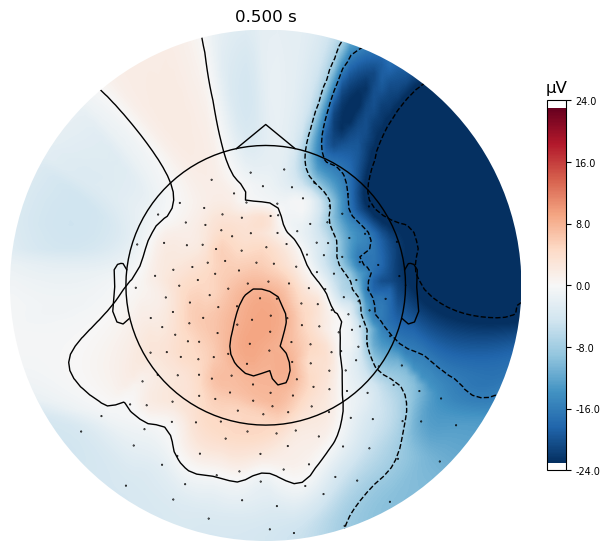

In [6]:
times = [0.5]
_ = data["eeg_inv"].plot_topomap(times=times, size=4)

#### 🌟 Visualize forward matrix

In [7]:
mm.viz.plot_leadfield(data["eeg_inv"], data["fwd"]).show()

    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]


Widget(value='<iframe src="http://localhost:34857/index.html?ui=P_0x79b610ab3b60_0&reconnect=auto" class="pyvi…

#### 🌟 Visualize connectome spectrum transform

In [8]:
signal = data["cst"][2]
max_abs = max(abs(signal.max()), abs(signal.min()))
clim    = [-max_abs, max_abs]
mm.viz.plot_brain_signal(data["fwd"]["src"], signal, clim=clim).show()

ValueError: Number of scalars (3078) must match either the number of points (3243) or the number of cells (3243).

🛠️ <font color=violet>**Select time points to reconstruct**</font>: CSET is an iterative process. This can be quite slow, so let's restrain the number of time points we reconstruct.

Number of time points: (204, 25)


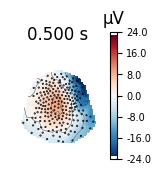

In [38]:
tmin  = 0.45
tmax  = 0.55
tviz  = 0.5
sfreq = eeg.info["sfreq"]

b = eeg.get_data("eeg", tmin=tmin, tmax=tmax)

print(f"Number of time points: {b.shape}")
_ = eeg.plot_topomap([tviz], outlines=None, extrapolate="local")

## Solve The Inverse Problem

⚙️ <font color=green>**Write the optimization problem**</font>: Using the `pyxu` package we can write down any optimization problem and then solve them.

In [39]:
# forward * connectome spectrum
A = fwd@cst.T

# Depth weighting
A_norms = np.linalg.norm(A, ord=2, axis=0)
A       = A/A_norms[None,:]

# data normalization
y_norms = np.linalg.norm(b, ord=2, axis=0)
y       = b/y_norms[None,:]

# initial guess
alpha0 = np.zeros(fwd.shape[1])

# operators
A       = pxa.LinOp.from_array(A)             
l1_norm = lam*pxo.L1Norm(dim_shape=alpha0.shape[0])

solution  = np.zeros((fwd.shape[1], b.shape[1]))
stop_crit = pxst.RelError(eps=1e-8, var="x", f=None, norm=2, satisfy_all=True)
for i in range(b.shape[1]):
    l22_loss = pxo.SquaredL2Norm(dim_shape=A.codim_shape[0]).argshift(-y[:,i]) * A
    l22_loss.diff_lipschitz = l22_loss.estimate_diff_lipschitz()

    solver = PGD(f=l22_loss, g=l1_norm, show_progress=False)

    solver.fit(x0=np.zeros(l22_loss.dim_shape), acceleration=True, stop_crit=stop_crit)
    
    alpha    = solver.solution().squeeze()
    solution[:,i] = cst.T@alpha*y_norms[i]*A_norms

#### <font color=yellow>🌟</font> Visualize reconstruction

In [40]:
mm.viz.plot_brain_time_series(forward["src"], np.abs(solution), sfreq, cmap="reds")

Widget(value='<iframe src="http://localhost:45913/index.html?ui=P_0x7fbdf9783ec0_19&reconnect=auto" class="pyv…

## 💾 Save result

In [9]:
save = "mne"
#save = "bv"

fname  = f"{sub}_cset-{lam}"
folder = mm_dir/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving estimation of subject: {sub}")
if save == "mne":
    vertices = [forward["src"][0]["vertno"], forward["src"][1]["vertno"]]
    stc = mne.SourceEstimate(solution, vertices, tmin=0, tstep=1/sfreq, subject=sub)
    stc.save(folder/fname, overwrite=True)
    
if save == "bv":
    trans = mm.utils.compute_transformation(sub, fs_dir, "mri", "head", "m")
    mm.io.write_stc(
        fname  = fname,
        folder = folder,
        stc    = stc, 
        src    = forward["src"],
        trans  = trans, 
        overwrite = True, 
    )

Writing STC to disk...
[done]
